In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import pickle
import os
from lmfit.models import VoigtModel
import ast
from specutils import Spectrum1D
from specutils.analysis import equivalent_width
import astropy.units as u
from astropy.table import Table
from functools import reduce
from scipy.stats import gaussian_kde
import cmasher as cmr


def spec_shift(waves, vel):
    """
    Performs radial shift on spectra.

    Parameters
    ----------
    waves : ndarray
        Wavelength array being shifted.

    vel : float
        Radial velocity value being used to perform the correction.

    Returns
    -------
    waves_shifted : ndarray
        Velocity-corrected wavelength array.
    """
    c = 299792.458

    # COMPUTING SHIFT IN LOG SPACE
    shift = np.log(1 + vel / c)

    # TRANSFORMING SHIFTED AXIS INTO WAVELENGTH SPACE
    waves_shifted = np.exp(np.log(waves) - shift)

    return waves_shifted

/home/benlowe/.local/lib/python3.9/site-packages/setuptools_scm/_integration/setuptools.py:31: RuntimeWarning: 
ERROR: setuptools==53.0.0 is used in combination with setuptools_scm>=8.x

Your build configuration is incomplete and previously worked by accident!
setuptools_scm requires setuptools>=61

Suggested workaround if applicable:
 - migrating from the deprecated setup_requires mechanism to pep517/518
   and using a pyproject.toml to declare build dependencies
   which are reliably pre-installed before running the build tools

  warnings.warn(


## Checking flux errors for ra_ra_0103-7050_s163 (1 OB)

Loading in the data and rv shifting the original spectra

In [ ]:
# Loading in the original un-porcessed data
ra_0103_data_og = Table.read('/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_0103-7050_s163/uvb/ADP.2024-06-19T11:49:45.770.fits')
ra_0103_wave_og = ra_0103_data_og['WAVE'].data[0]
ra_0103_flux_og = ra_0103_data_og['FLUX_REDUCED'].data[0]
ra_0103_flux_err_og = ra_0103_data_og['ERR_REDUCED'].data[0]

# Radial velocity shifting the original spectra
ra_0103_rv = -37.82571959261978
ra_0103_wave_og = spec_shift(ra_0103_wave_og * 10, ra_0103_rv) 

# Loading in the processed data
ra_0103_data_up = Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_0103-7050_s163/ra_0103-7050_s163_data.fits', hdu=1)
ra_0103_wave_up = ra_0103_data_up['wave'].data
ra_0103_flux_up = ra_0103_data_up['flux'].data
ra_0103_flux_err_up = ra_0103_data_up['flux_err'].data

# Cutting the data to our desired wavelength range
wave_min = 4600
wave_max = 4620

ra_0103_waveindex_og = (ra_0103_wave_og > wave_min) & (ra_0103_wave_og < wave_max)
ra_0103_wavecut_og = ra_0103_wave_og[ra_0103_waveindex_og]
ra_0103_fluxcut_og = ra_0103_flux_og[ra_0103_waveindex_og]

ra_0103_waveindex_up = (ra_0103_wave_up > wave_min) & (ra_0103_wave_up < wave_max)
ra_0103_wavecut_up = ra_0103_wave_up[ra_0103_waveindex_up]
ra_0103_fluxcut_up = ra_0103_flux_up[ra_0103_waveindex_up]

Plotting the two together

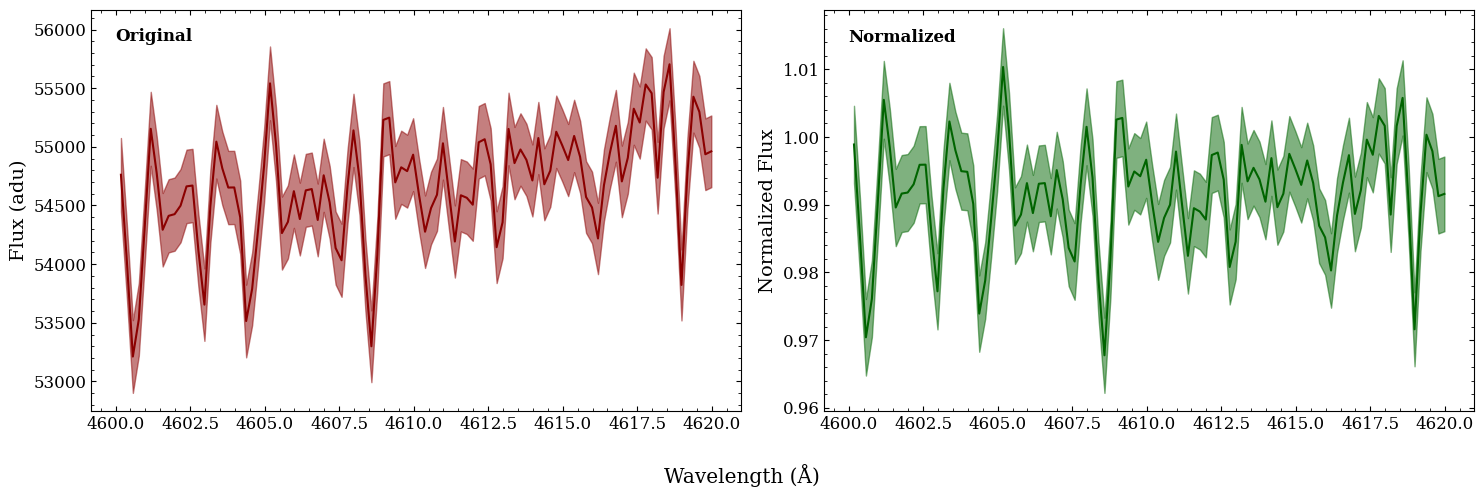

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), tight_layout=True)
fig.supxlabel('Wavelength (Å)')

ax[0].plot(ra_0103_wavecut_og, ra_0103_fluxcut_og, color='darkred', label='Original')
ax[0].fill_between(ra_0103_wavecut_og, ra_0103_fluxcut_og - ra_0103_flux_err_og[ra_0103_waveindex_og], ra_0103_fluxcut_og + ra_0103_flux_err_og[ra_0103_waveindex_og], color='darkred', alpha=0.5)
ax[0].set_ylabel('Flux (adu)')
ax[0].text(4600, 55900, 'Original', fontsize=12, fontweight='bold')

ax[1].plot(ra_0103_wavecut_up, ra_0103_fluxcut_up, label='Processed', color='darkgreen')
ax[1].fill_between(ra_0103_wavecut_up, ra_0103_fluxcut_up - ra_0103_flux_err_up[ra_0103_waveindex_up], ra_0103_fluxcut_up + ra_0103_flux_err_up[ra_0103_waveindex_up], alpha=0.5, color='darkgreen')
ax[1].set_ylabel('Normalized Flux')
ax[1].text(4600, 1.014, 'Normalized', fontsize=12, fontweight='bold')
plt.savefig('/data/misfit/benlowe/results/flux_err_checks/1OB_check.png', dpi=300, transparent=False, facecolor="white")

## Checking if multiple OB errors are correctly combined to get the final one

Loading in the data

In [5]:
# Loading in the original un-porcessed data
ra_1624_data_og1 = Table.read('/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1624-2150_s278/uvb/ADP.2024-08-06T08:21:34.980.fits')
ra_1624_wave_og1 = ra_1624_data_og1['WAVE'].data[0]
ra_1624_flux_og1 = ra_1624_data_og1['FLUX_REDUCED'].data[0]
ra_1624_flux_err_og1 = ra_1624_data_og1['ERR_REDUCED'].data[0]
ra_1624_norm_og1 = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/norm_spec/all/ra_1624-2150_s278/uvb/ra_1624-2150_s278_uvb_ob1.csv')
ra_1624_wavenorm_og1 = ra_1624_norm_og1['wave'].to_numpy()
ra_1624_fluxnorm_og1 = ra_1624_norm_og1['flux'].to_numpy()

ra_1624_data_og2 = Table.read('/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1624-2150_s278/uvb/ADP.2024-08-06T08:23:52.700.fits')
ra_1624_wave_og2 = ra_1624_data_og2['WAVE'].data[0]
ra_1624_flux_og2 = ra_1624_data_og2['FLUX_REDUCED'].data[0]
ra_1624_flux_err_og2 = ra_1624_data_og2['ERR_REDUCED'].data[0]
ra_1624_norm_og2 = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/norm_spec/all/ra_1624-2150_s278/uvb/ra_1624-2150_s278_uvb_ob2.csv')
ra_1624_wavenorm_og2 = ra_1624_norm_og2['wave'].to_numpy()
ra_1624_fluxnorm_og2 = ra_1624_norm_og2['flux'].to_numpy()

ra_1624_data_og3 = Table.read('/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1624-2150_s278/uvb/ADP.2024-08-06T08:26:26.025.fits')
ra_1624_wave_og3 = ra_1624_data_og3['WAVE'].data[0]
ra_1624_flux_og3 = ra_1624_data_og3['FLUX_REDUCED'].data[0]
ra_1624_flux_err_og3 = ra_1624_data_og3['ERR_REDUCED'].data[0]
ra_1624_norm_og3 = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/norm_spec/all/ra_1624-2150_s278/uvb/ra_1624-2150_s278_uvb_ob3.csv')
ra_1624_wavenorm_og3 = ra_1624_norm_og3['wave'].to_numpy()
ra_1624_fluxnorm_og3 = ra_1624_norm_og3['flux'].to_numpy()

# Radial velocity shifting the original spectra
ra_1624_rv = 233.17530626232835
ra_1624_wave_og1 = spec_shift(ra_1624_wave_og1 * 10, ra_1624_rv)
ra_1624_wavenorm_og1 = spec_shift(ra_1624_wavenorm_og1, ra_1624_rv)
ra_1624_wave_og2 = spec_shift(ra_1624_wave_og2 * 10, ra_1624_rv)
ra_1624_wavenorm_og2 = spec_shift(ra_1624_wavenorm_og2, ra_1624_rv)
ra_1624_wave_og3 = spec_shift(ra_1624_wave_og3 * 10, ra_1624_rv) 
ra_1624_wavenorm_og3 = spec_shift(ra_1624_wavenorm_og3, ra_1624_rv)

# Loading in the processed data
ra_1624_data_up = Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec_old/ra_1624-2150_s278/ra_1624-2150_s278_data.fits', hdu=1)
ra_1624_wave_up = ra_1624_data_up['wave'].data
ra_1624_flux_up = ra_1624_data_up['flux'].data
ra_1624_flux_err_up = ra_1624_data_up['flux_err'].data

# Cutting the data to our desired wavelength range
wave_min = 4610
wave_max = 4615

ra_1624_waveindex_og1 = (ra_1624_wave_og1 > wave_min) & (ra_1624_wave_og1 < wave_max)
ra_1624_wavecut_og1 = ra_1624_wave_og1[ra_1624_waveindex_og1]
ra_1624_fluxcut_og1 = ra_1624_flux_og1[ra_1624_waveindex_og1]
ra_1624_wavenorm_index_og1 = (ra_1624_wavenorm_og1 > wave_min) & (ra_1624_wavenorm_og1 < wave_max)
ra_1624_wavenormcut_og1 = ra_1624_wavenorm_og1[ra_1624_wavenorm_index_og1]
ra_1624_fluxnormcut_og1 = ra_1624_fluxnorm_og1[ra_1624_wavenorm_index_og1]

ra_1624_waveindex_og2 = (ra_1624_wave_og2 > wave_min) & (ra_1624_wave_og2 < wave_max)
ra_1624_wavecut_og2 = ra_1624_wave_og2[ra_1624_waveindex_og2]
ra_1624_fluxcut_og2 = ra_1624_flux_og2[ra_1624_waveindex_og2]
ra_1624_wavenorm_index_og2 = (ra_1624_wavenorm_og2 > wave_min) & (ra_1624_wavenorm_og2 < wave_max)
ra_1624_wavenormcut_og2 = ra_1624_wavenorm_og2[ra_1624_wavenorm_index_og2]
ra_1624_fluxnormcut_og2 = ra_1624_fluxnorm_og2[ra_1624_wavenorm_index_og2]

ra_1624_waveindex_og3 = (ra_1624_wave_og1 > wave_min) & (ra_1624_wave_og1 < wave_max)
ra_1624_wavecut_og3 = ra_1624_wave_og3[ra_1624_waveindex_og3]
ra_1624_fluxcut_og3 = ra_1624_flux_og3[ra_1624_waveindex_og3]
ra_1624_wavenorm_index_og3 = (ra_1624_wavenorm_og3 > wave_min) & (ra_1624_wavenorm_og3 < wave_max)
ra_1624_wavenormcut_og3 = ra_1624_wavenorm_og3[ra_1624_wavenorm_index_og3]
ra_1624_fluxnormcut_og3 = ra_1624_fluxnorm_og3[ra_1624_wavenorm_index_og3]

ra_1624_waveindex_up = (ra_1624_wave_up > wave_min) & (ra_1624_wave_up < wave_max)
ra_1624_wavecut_up = ra_1624_wave_up[ra_1624_waveindex_up]
ra_1624_fluxcut_up = ra_1624_flux_up[ra_1624_waveindex_up]

smooth1 = ra_1624_fluxcut_og1/ra_1624_fluxnormcut_og1
smooth2 = ra_1624_fluxcut_og2/ra_1624_fluxnormcut_og2
smooth3 = ra_1624_fluxcut_og3/ra_1624_fluxnormcut_og3
fluxnorm_err1 = ra_1624_flux_err_og1[ra_1624_waveindex_og1] / smooth1
fluxnorm_err2 = ra_1624_flux_err_og2[ra_1624_waveindex_og2] / smooth2
fluxnorm_err3 = ra_1624_flux_err_og3[ra_1624_waveindex_og3] / smooth3

Plotting

(0.95, 1.02)

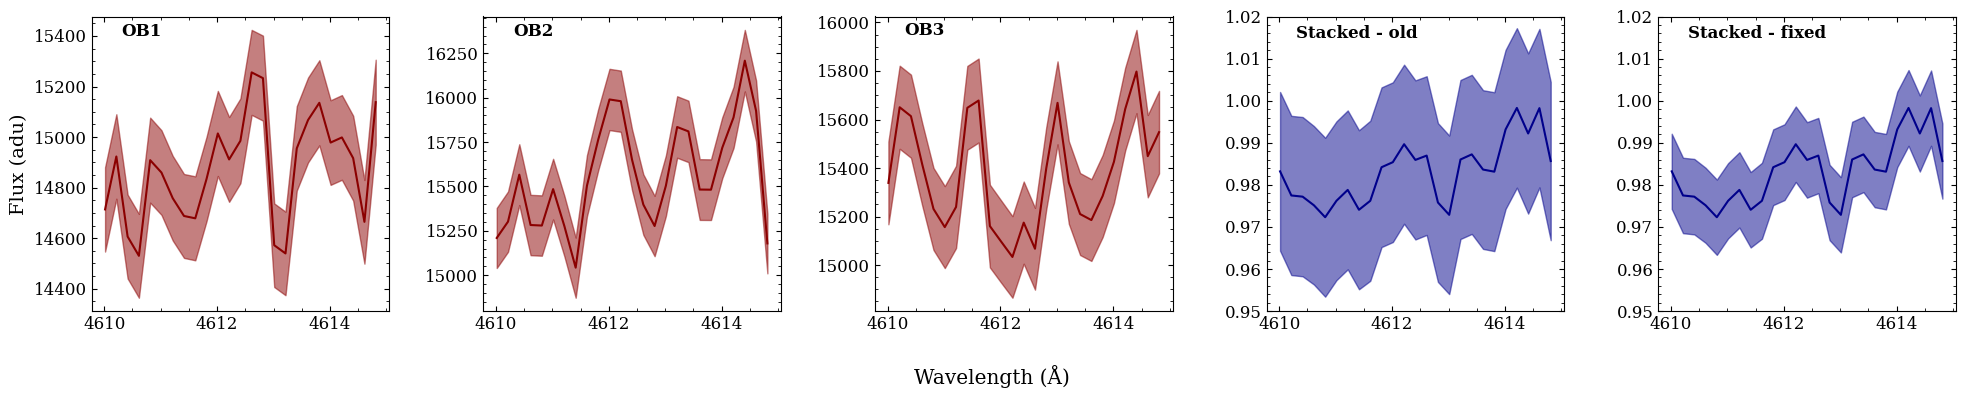

In [6]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4), tight_layout=True)
fig.supxlabel('Wavelength (Å)')

ax[0].plot(ra_1624_wavecut_og1, ra_1624_fluxcut_og1, color='darkred', label='Original')
ax[0].fill_between(ra_1624_wavecut_og1, ra_1624_fluxcut_og1 - ra_1624_flux_err_og1[ra_1624_waveindex_og1], ra_1624_fluxcut_og1 + ra_1624_flux_err_og1[ra_1624_waveindex_og1], color='darkred', alpha=0.5)
ax[0].set_ylabel('Flux (adu)')
ax[0].text(4610.3, 15400, 'OB1', fontsize=12, fontweight='bold')
# ax[0].text(4600, 55900, 'Original', fontsize=12, fontweight='bold')

ax[1].plot(ra_1624_wavecut_og2, ra_1624_fluxcut_og2, color='darkred', label='Original')
ax[1].fill_between(ra_1624_wavecut_og2, ra_1624_fluxcut_og2 - ra_1624_flux_err_og2[ra_1624_waveindex_og2], ra_1624_fluxcut_og2 + ra_1624_flux_err_og2[ra_1624_waveindex_og2], color='darkred', alpha=0.5)
ax[1].text(4610.3, 16350, 'OB2', fontsize=12, fontweight='bold')

ax[2].plot(ra_1624_wavecut_og3, ra_1624_fluxcut_og3, color='darkred', label='Original')
ax[2].fill_between(ra_1624_wavecut_og3, ra_1624_fluxcut_og3 - ra_1624_flux_err_og3[ra_1624_waveindex_og3], ra_1624_fluxcut_og3 + ra_1624_flux_err_og3[ra_1624_waveindex_og3], color='darkred', alpha=0.5)
ax[2].text(4610.3, 15950, 'OB3', fontsize=12, fontweight='bold')

ax[3].plot(ra_1624_wavecut_up, ra_1624_fluxcut_up, color='darkblue', label='Original')
ax[3].fill_between(ra_1624_wavecut_up, ra_1624_fluxcut_up - ra_1624_flux_err_up[ra_1624_waveindex_up], ra_1624_fluxcut_up + ra_1624_flux_err_up[ra_1624_waveindex_up], color='darkblue', alpha=0.5)
ax[3].text(4610.3, 1.015, 'Stacked - old', fontsize=12, fontweight='bold')
ax[3].set_ylim(top=1.02, bottom=0.95)

fluxnorm_errcomb = np.sqrt(fluxnorm_err1**2 + fluxnorm_err2**2 + fluxnorm_err3**2)/3
ax[4].plot(ra_1624_wavecut_up, ra_1624_fluxcut_up, color='darkblue', label='Original')
ax[4].fill_between(ra_1624_wavecut_up, ra_1624_fluxcut_up - fluxnorm_errcomb, ra_1624_fluxcut_up + fluxnorm_errcomb, color='darkblue', alpha=0.5)
ax[4].text(4610.3, 1.015, 'Stacked - fixed', fontsize=12, fontweight='bold')
ax[4].set_ylim(top=1.02, bottom=0.95)

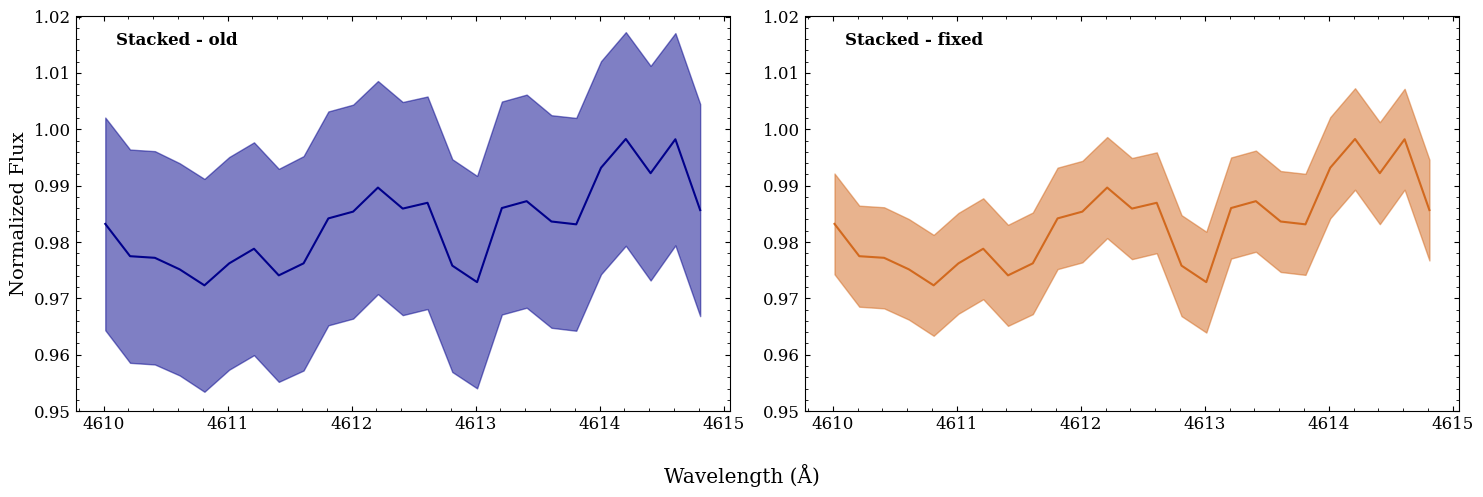

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), tight_layout=True)
fig.supxlabel('Wavelength (Å)')


ax[0].plot(ra_1624_wavecut_up, ra_1624_fluxcut_up, color='darkblue', label='Original')
ax[0].fill_between(ra_1624_wavecut_up, ra_1624_fluxcut_up - ra_1624_flux_err_up[ra_1624_waveindex_up], ra_1624_fluxcut_up + ra_1624_flux_err_up[ra_1624_waveindex_up], color='darkblue', alpha=0.5)
ax[0].text(4610.1, 1.015, 'Stacked - old', fontsize=12, fontweight='bold')
ax[0].set_ylim(top=1.02, bottom=0.95)
ax[0].set_ylabel('Normalized Flux')

fluxnorm_errcomb = np.sqrt(fluxnorm_err1**2 + fluxnorm_err2**2 + fluxnorm_err3**2)/3
ax[1].plot(ra_1624_wavecut_up, ra_1624_fluxcut_up, color='chocolate', label='Original')
ax[1].fill_between(ra_1624_wavecut_up, ra_1624_fluxcut_up - fluxnorm_errcomb, ra_1624_fluxcut_up + fluxnorm_errcomb, color='chocolate', alpha=0.5)
ax[1].text(4610.1, 1.015, 'Stacked - fixed', fontsize=12, fontweight='bold')
ax[1].set_ylim(top=1.02, bottom=0.95)
plt.savefig('/data/misfit/benlowe/results/flux_err_checks/stack_error_check.png', dpi=300, transparent=False, facecolor="white")

In [52]:
# print("OB1")
# print(ra_1624_flux_err_og1[ra_1624_waveindex_og1])
# print("OB2")
# print(ra_1624_flux_err_og2[ra_1624_waveindex_og2])
# print("OB3")
# print(ra_1624_flux_err_og3[ra_1624_waveindex_og3])

# print()
# print("Comb")
smooth1 = ra_1624_fluxcut_og1/ra_1624_fluxnormcut_og1
smooth2 = ra_1624_fluxcut_og2/ra_1624_fluxnormcut_og2
smooth3 = ra_1624_fluxcut_og3/ra_1624_fluxnormcut_og3

fluxnorm_err1 = ra_1624_flux_err_og1[ra_1624_waveindex_og1] / smooth1
fluxnorm_err2 = ra_1624_flux_err_og2[ra_1624_waveindex_og2] / smooth2
fluxnorm_err3 = ra_1624_flux_err_og3[ra_1624_waveindex_og3] / smooth3

print(fluxnorm_err1)
print(fluxnorm_err2)
print(fluxnorm_err3)
print(ra_1624_flux_err_up[ra_1624_waveindex_up])
print(np.sqrt(fluxnorm_err1**2 + fluxnorm_err2**2 + fluxnorm_err3**2)/3)
# np.sqrt(ra_1624_flux_err_og1[ra_1624_waveindex_og1]**2 + ra_1624_flux_err_og2[ra_1624_waveindex_og2]**2 + ra_1624_flux_err_og3[ra_1624_waveindex_og3]**2)/3


[0.0157113  0.01574158 0.01562945 0.01562378 0.01583817 0.01576992
 0.01576168 0.0156345  0.01565455 0.01572168 0.01585741 0.01580987
 0.01579823 0.01583935 0.01584379 0.01557784 0.01556905 0.01572658
 0.01582188 0.01586223 0.0157719  0.01578406 0.01580953 0.01559447
 0.015832  ]
[0.01514538 0.01520008 0.01533339 0.0152106  0.01521245 0.01527472
 0.01526424 0.01515811 0.01541972 0.01546969 0.01544315 0.01543171
 0.01534822 0.01524718 0.01521206 0.01528898 0.01549979 0.01548953
 0.01531068 0.01528436 0.01535632 0.015402   0.01550901 0.01540113
 0.0151026 ]
[0.01556316 0.01561852 0.01561737 0.01550549 0.0154271  0.01540356
 0.01546432 0.0157453  0.01577089 0.01554616 0.01545392 0.01532781
 0.01544698 0.01538086 0.01545904 0.01559136 0.01551712 0.01540066
 0.01536752 0.01541536 0.0155007  0.01557231 0.0156585  0.01547916
 0.01551049]
[0.01885996 0.01891442 0.01891913 0.01881959 0.01887495 0.01885989
 0.01887429 0.01889104 0.0190123  0.01896666 0.0189724  0.01889549
 0.01890209 0.01884959 

In [49]:
ra_1624_fluxcut_og1

array([14713.63964844, 14923.13378906, 14606.13378906, 14529.97558594,
       14908.58007812, 14859.51269531, 14757.94433594, 14687.70800781,
       14678.40820312, 14834.42578125, 15014.28613281, 14911.40234375,
       14985.03710938, 15255.91699219, 15233.16992188, 14571.97851562,
       14539.41210938, 14955.17578125, 15067.44726562, 15135.52246094,
       14978.18457031, 14998.51855469, 14916.49609375, 14664.49804688,
       15138.01757812], dtype='>f8')

## Comapring the original fit (no masking) with the new fit (masking)

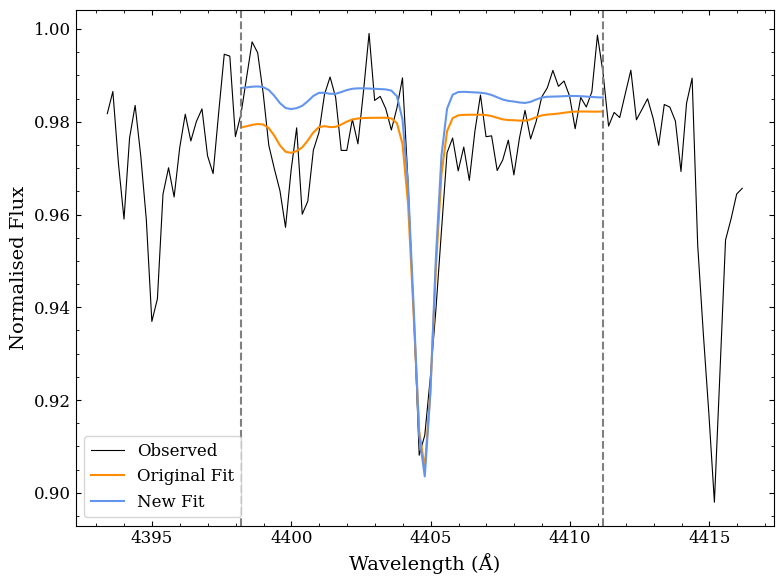

In [6]:
# Loading in the data
og_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/stars_v2/test_wider_wind/ra_1633-2814_s284/Fe/iter_2/Fe_results.csv')
new_data = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/tests/stars_v3/new_data/ra_1633-2814_s284/Fe/iter_1/Fe_results.csv')

# Getting the original fit data
og_fitwave = og_data[og_data['line'] == 'Fe_4404.75']['fit_wave'].apply(ast.literal_eval).to_numpy()[0][0]
og_fitflux = og_data[og_data['line'] == 'Fe_4404.75']['fit_flux'].apply(ast.literal_eval).to_numpy()[0][0]

# Getting the new fit data
new_fitwave = new_data[new_data['line'] == 'Fe_4404.75']['fit_wave'].apply(ast.literal_eval).to_numpy()[0][0]
new_fitflux = new_data[new_data['line'] == 'Fe_4404.75']['fit_flux'].apply(ast.literal_eval).to_numpy()[0][0]

# Getting the observed data
obs_wave = og_data[og_data['line'] == 'Fe_4404.75']['obs_wave'].apply(ast.literal_eval).to_numpy()[0][0]
obs_flux = og_data[og_data['line'] == 'Fe_4404.75']['obs_flux'].apply(ast.literal_eval).to_numpy()[0][0]

# Plotting
plt.figure(figsize=[8, 6])
plt.plot(obs_wave, obs_flux, color='black', label='Observed', linewidth=0.8)
plt.plot(og_fitwave, og_fitflux, color='darkorange', label='Original Fit', linewidth=1.5)
plt.plot(new_fitwave, new_fitflux, color='cornflowerblue', label='New Fit', linewidth=1.5)
plt.axvline(min(og_fitwave), color="grey", linestyle="--")
plt.axvline(max(og_fitwave), color="grey", linestyle="--")
plt.xlabel("Wavelength (Å)")
plt.ylabel("Normalised Flux")
plt.legend(fancybox=True)
plt.tight_layout()
# plt.savefig('/data/misfit/benlowe/xshooter/korg_data/stars_v3/fit_compare.png', dpi=300, transparent=False, facecolor="white")

## Getting the bottom 10% of the Ca-II triplet 

[8541.81211455 8542.01199783 8542.21188111]
[0.73132004 0.66695509 0.67503648]


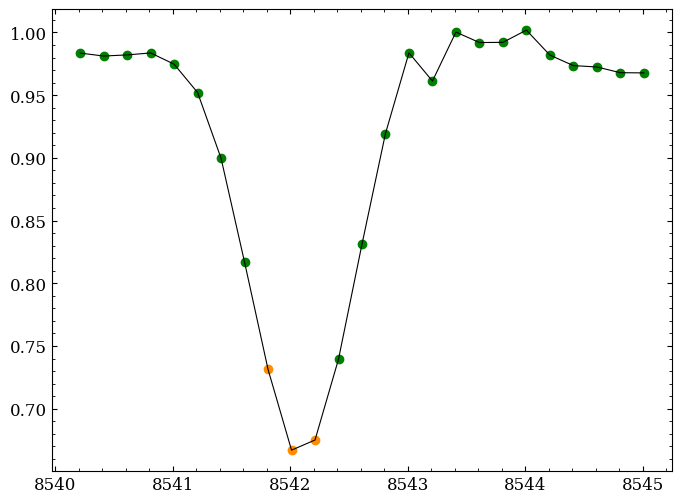

In [6]:
# Loading in example data
test_data = Table.read('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1633-2814_s284/ra_1633-2814_s284_data.fits', hdu=2)


# Ca 2,8498.02,8488.02,8508.02
# Ca 2,8542.198,8532.198,8552.198
# Ca 2,8662.138,8652.138,8672.138

wavemin = 8540.198
wavemax = 8545.198
test_wave = test_data['wave'].data

# Slicing the data to only include the first line of the Ca-II triplet
waveindex = np.where((test_wave > wavemin) & (test_wave < wavemax))

caII_wave = test_data['wave'].data[waveindex]
caII_flux = test_data['flux'].data[waveindex]
caII_flux_err = test_data['flux_err'].data[waveindex]

# Masking out the bottom 5% of the absorption line
minflux = np.percentile(caII_flux, 10)
bad_region = np.where(caII_flux <= minflux)
good_region = np.where(caII_flux > minflux)

goodwave = caII_wave[good_region]
goodflux = caII_flux[good_region]
badwave = caII_wave[bad_region]
badflux = caII_flux[bad_region]

print(badwave)
print(badflux)

plt.figure(figsize=[8,6])
plt.scatter(goodwave, goodflux, color='green', label='Good')
plt.scatter(badwave, badflux, color='darkorange', label='Mask')
plt.plot(caII_wave, caII_flux, color='black', label='Observed', linewidth=0.8)